# SANOS DLV Kalman Filter Evaluation

Two-stage pipeline in **absolute strike space**:
1. **Batch DLV fit** — at each time bucket (5m / 1m / 1s) run the SANOS absolute-strike
   optimizer to get DLV² values `dlvsqs ∈ ℝ^{N_interior}` (same as `sanos_dlv_intraday_own_absolute`).
2. **Linear Kalman filter on DLV²** — treat each batch DLV² vector as a noisy observation
   of the latent true DLV² state. Random-walk transition; observation matrix H = I.

Sections: data loading → DLV fitting → KF loop → diagnostics & visualisation.

## Section 0 — Setup & data loading

In [1]:
import datetime as _dt
import os
import sys
from datetime import date
from functools import partial
from zoneinfo import ZoneInfo

import matplotlib.colors as mcolors
import matplotlib.pyplot as plt
import numpy as np
import polars as pl

project_root = "/Users/elie/Documents/GitHub/quant_data/"
kf_dir = os.path.join(project_root, "personal", "Kalman_filter_spline")
sanos_kf_dir = os.path.join(project_root, "personal", "SANOS_KF_Strike")
for p in [project_root, kf_dir, sanos_kf_dir]:
    if p not in sys.path:
        sys.path.insert(0, p)

os.environ.setdefault("QUANTDATA_RAW_DATA", "/quantdata/raw")

from dlv_fit_absolute import SolverError, fit_density
from dlv_grid_absolute import make_density0, make_strike_grid
from dlv_pricing_absolute import (
    call_prices,
    iv_from_norm_call,
    iv_from_norm_put,
    option_prices,
    put_prices,
    v_atm_from_price,
)
from dlv_snapshot_absolute import make_batch_snapshots, run_intraday_loop

from personal.Kalman_filter_spline.surface_kalman_filters import build_iv_observations
from quantdata.massive.client import MassiveClient

%matplotlib inline
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

_ny = ZoneInfo("America/New_York")

/Users/elie/Documents/GitHub/quant_data/quantdata/__init__.py:212: UserWarning: Using cache mode 'on' as specified in environment variable QUANTDATA_CACHE_MODE.


In [17]:
# ── Configuration ─────────────────────────────────────────────────────────
TICKER = "SPY"
TRADE_DATE = date(2024, 1, 3)
BATCH_FREQ = "1s"  # "1s" | "1m" | "5m"
MIN_TRADES = 100
N_VIZ = 6  # number of snapshot curves in IV smile plots

# DLV grid geometry
LOWER_SCALE = 0.9
UPPER_SCALE = 1.1
N_PAD = 1
DLV_MIN = 0.001
DLV_MAX = 2.0
CALLS_ONLY = True
PUTS_ONLY = False

# DLV optimizer
REGULARIZER_WEIGHT = 1e-3
LOG_DLV_SPACE = False
TEMPORAL_REGULARIZER_WEIGHT = 1.0
TEMPORAL_WEIGHT_CLIP = 100.0
BID_ASK_PENALTY_WEIGHT = 0.0

# Kalman filter hyperparameters
KF_Q_SCALE = 1e-6  # process noise variance per trading day (per DLV² component)
KF_R_DIAG = 1e-4  # observation noise variance (per DLV² component)
KF_P0_SCALE = 1e-3  # initial posterior covariance diagonal
TRADING_DAY_S = 23400.0  # 6.5 h in seconds

In [18]:
df_tickers = pl.read_csv(os.path.join(project_root, "personal", "spy_options_tickers.csv"))

client = MassiveClient()
df_spy = client.fetch_trades(TICKER, TRADE_DATE)

df_quotes_all, df_trades_all = build_iv_observations(
    df_tickers, TRADE_DATE, df_spy, min_trades=MIN_TRADES
)
df_quotes_all = df_quotes_all.drop_nulls()

print(f"quotes: {len(df_quotes_all):,}   trades: {len(df_trades_all):,}")
df_quotes_all.head(3)

Skipping O:SPY240105C00481000: 46 bad quotes
Skipping O:SPY240105C00482000: 64 bad quotes
Skipping O:SPY240105C00483000: 842 bad quotes
Skipping O:SPY240105C00484000: 2129 bad quotes
Skipping O:SPY240105C00485000: 3888 bad quotes
Skipping O:SPY240105P00462500: 17 bad quotes
Expiry 2024-01-05: implied forward from 13 strike(s)
quotes: 2,115,471   trades: 74,099


ts_ns,strike,is_call,log_moneyness,T,observed_iv,bid_iv,ask_iv,R_iv,bid_price,ask_price,forward,discount_factor
"datetime[ns, America/New_York]",f64,bool,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
2024-01-03 09:30:00.146414080 EST,471.0,true,0.00054,0.006217,0.13906,0.138046,0.140074,0.000001,1.92,1.95,470.745509,1.002
2024-01-03 09:30:00.147911936 EST,458.0,false,-0.027448,0.006217,0.179262,0.176954,0.181464,0.000005,0.06,0.07,470.745509,1.002
2024-01-03 09:30:00.149571328 EST,475.0,true,0.008997,0.006217,0.133718,0.13226,0.135163,0.000002,0.53,0.56,470.745509,1.002


In [19]:
# Normalise prices by discount factor (absolute-strike convention: C/df, P/df)
has_df = "discount_factor" in df_quotes_all.columns
df_scale = pl.col("discount_factor") if has_df else pl.lit(1.0)

df_q = df_quotes_all.with_columns(
    (pl.col("bid_price") / df_scale).alias("bid_norm"),
    (pl.col("ask_price") / df_scale).alias("ask_norm"),
    ((pl.col("bid_price") + pl.col("ask_price")) / 2.0 / df_scale).alias("mid_norm"),
    pl.col("strike").alias("pure_strike"),
)

df_calls = df_q.filter(pl.col("is_call"))
df_puts = df_q.filter(~pl.col("is_call"))

tte_y_max = float(df_q["T"].max())
tte_y_med = float(df_q["T"].median())
print(f"calls: {len(df_calls):,}   puts: {len(df_puts):,}")
print(f"T range: [{df_q['T'].min():.5f}, {tte_y_max:.5f}]  median={tte_y_med:.5f}")

calls: 956,381   puts: 1,159,090
T range: [0.00545, 0.00622]  median=0.00582


## Section 1 — Strike grid & DLV batch fitting

In [20]:
tte_geom = tte_y_max * 1.1
df_anchor = df_puts if PUTS_ONLY else df_calls
ref_fwd = float(df_anchor["forward"].median())
obs_ks = np.sort(df_anchor["strike"].unique().to_numpy().astype(float))

grid = make_strike_grid(
    obs_ks, fwd=ref_fwd, lower_scale=LOWER_SCALE, upper_scale=UPPER_SCALE, n_pad=N_PAD
)
xstrikes_row = grid["xstrikes_row"]
anchor_pure = grid["anchor_pure"]  # (N,) all interior anchors incl. pads
interior_pure = grid["interior_pure"]
anchor_lk = np.log(anchor_pure / ref_fwd)
interior_lk = np.log(interior_pure / ref_fwd)

grid_K, density0 = make_density0(xstrikes_row, fwd=ref_fwd)

_fit_fn = partial(
    fit_density,
    xstrikes_row=xstrikes_row,
    grid_K=grid_K,
    density0=density0,
    tte_geom=tte_geom,
    dlv_min=DLV_MIN,
    dlv_max=DLV_MAX,
    regularizer_weight=REGULARIZER_WEIGHT,
    log_dlv_space=LOG_DLV_SPACE,
    temporal_regularizer_weight=TEMPORAL_REGULARIZER_WEIGHT,
    temporal_weight_clip=TEMPORAL_WEIGHT_CLIP,
    bid_ask_penalty_weight=BID_ASK_PENALTY_WEIGHT,
)

N_interior = len(grid_K)  # total interior anchors (including pads)
# dlvsqs from fit_density are (N-2,): boundary anchors have box=0 and are excluded
dlv_anchor_pure = anchor_pure[1:-1]  # (N-2,) strikes corresponding to DLV² state
N_dlv = len(dlv_anchor_pure)

print(f"Grid: {N_interior} interior anchors (N_dlv={N_dlv} DLV² state dims) + 2 boundaries")
print(f"  ref_fwd:   {ref_fwd:.4f}")
print(f"  anchors:   [{anchor_pure[0]:.2f}, {anchor_pure[-1]:.2f}]")
print(f"  interior:  [{interior_pure[0]:.2f}, {interior_pure[-1]:.2f}]")

Grid: 19 interior anchors (N_dlv=17 DLV² state dims) + 2 boundaries
  ref_fwd:   470.0629
  anchors:   [431.30, 504.00]
  interior:  [454.00, 480.00]


In [21]:
snaps_calls = make_batch_snapshots(df_calls, BATCH_FREQ)
snaps_puts = make_batch_snapshots(df_puts, BATCH_FREQ)
snap_ref = snaps_puts if PUTS_ONLY else snaps_calls
batch_ts_list = sorted(snap_ref["batch_ts"].unique().to_list())
print(f"{len(batch_ts_list)} snapshots at {BATCH_FREQ} frequency")
print(f"first: {batch_ts_list[0]}   last: {batch_ts_list[-1]}")

23995 snapshots at 1s frequency
first: 2024-01-03 09:30:00-05:00   last: 2024-01-03 16:14:59-05:00


In [22]:
try:
    from tqdm.auto import tqdm
except ImportError:

    def tqdm(x, **kw):
        return x


results = run_intraday_loop(
    batch_ts_list=tqdm(batch_ts_list, desc="Fitting DLV snapshots"),
    snaps_calls=snaps_calls,
    snaps_puts=snaps_puts,
    fit_fn=_fit_fn,
    tte_y_med=tte_y_med,
    calls_only=CALLS_ONLY,
    puts_only=PUTS_ONLY,
    verbose=False,
)

good = [r for r in results if not r["failed"]]
n_failed = sum(r["failed"] for r in results)
print(f"Done. Failed: {n_failed}/{len(results)}")

Done. Failed: 0/23995


## Section 2 — Linear Kalman filter on DLV²

**Model:**
- State  `x ∈ ℝ^{N_interior}` = true DLV² at interior anchors
- Transition: random walk `x_{k+1} = x_k + w`,  `w ~ N(0, Q)`,  `Q = KF_Q_SCALE · Δt_days · I`
- Observation: `z = dlvsqs` from batch fit → `z = x + v`,  `v ~ N(0, R)`,  `R = KF_R_DIAG · I`
- Observation matrix H = I  → gain `K = P_pred (P_pred + R)⁻¹`
- Failed snapshots: predict-only step (no update).

In [23]:
def _ts_seconds(r):
    """Return snapshot timestamp as POSIX seconds."""
    ts = r["ts"]
    return ts.timestamp() if hasattr(ts, "timestamp") else float(ts) / 1e9


def run_dlv_kalman_filter(results, N_dlv, Q_scale, R_diag, P0_scale, trading_day_s):
    """
    Linear KF on DLV² vectors.

    Parameters
    ----------
    N_dlv : int
        Dimension of DLV² state = len(grid_K) - 2  (boundary anchors excluded)

    Returns
    -------
    x_hist       : (T, N_dlv)  posterior mean DLV²
    x_pred_hist  : (T, N_dlv)  prior mean DLV²
    P_diag_hist  : (T, N_dlv)  posterior covariance diagonal
    innov_hist   : (T, N_dlv)  innovation z - x_pred (NaN on failed snapshots)
    ts_hist      : (T,)        POSIX seconds per step
    failed_hist  : (T,) bool   whether snapshot DLV fit failed
    """
    n = N_dlv
    R = R_diag * np.eye(n)
    I = np.eye(n)

    # Initialise from first non-failed snapshot
    init = next(r for r in results if not r["failed"])
    x = init["dlvsqs"][0].copy()  # (n,) — shape (N-2,)
    P = P0_scale * I
    t_prev = _ts_seconds(init)

    x_hist = np.empty((len(results), n))
    x_pred_hist = np.empty((len(results), n))
    P_diag_hist = np.empty((len(results), n))
    innov_hist = np.full((len(results), n), np.nan)
    ts_hist = np.empty(len(results))
    failed_hist = np.empty(len(results), dtype=bool)

    for k, r in enumerate(results):
        t_k = _ts_seconds(r)
        dt_s = max(t_k - t_prev, 0.0)
        dt_days = dt_s / trading_day_s

        # ── Predict ──
        Q = Q_scale * dt_days * I
        x_pred = x.copy()
        P_pred = P + Q

        ts_hist[k] = t_k
        failed_hist[k] = r["failed"]

        if r["failed"] or r["dlvsqs"] is None:
            # No observation → stay at prior
            x = x_pred
            P = P_pred
        else:
            z = r["dlvsqs"][0].copy()  # (n,) = (N-2,)
            y = z - x_pred  # innovation
            S = P_pred + R  # innovation covariance (H=I)
            K_gain = P_pred @ np.linalg.inv(S)
            x = x_pred + K_gain @ y
            # Joseph form for numerical stability
            IKH = I - K_gain
            P = IKH @ P_pred @ IKH.T + K_gain @ R @ K_gain.T
            innov_hist[k] = y

        x_hist[k] = x
        x_pred_hist[k] = x_pred
        P_diag_hist[k] = np.diag(P)
        t_prev = t_k

    return x_hist, x_pred_hist, P_diag_hist, innov_hist, ts_hist, failed_hist


x_hist, x_pred_hist, P_diag_hist, innov_hist, ts_hist, failed_hist = run_dlv_kalman_filter(
    results,
    N_dlv=N_dlv,
    Q_scale=KF_Q_SCALE,
    R_diag=KF_R_DIAG,
    P0_scale=KF_P0_SCALE,
    trading_day_s=TRADING_DAY_S,
)

# Raw DLV² matrix (NaN on failed snapshots) — shape (T, N_dlv)
raw_dlvsq = np.full((len(results), N_dlv), np.nan)
for k, r in enumerate(results):
    if not r["failed"] and r["dlvsqs"] is not None:
        raw_dlvsq[k] = r["dlvsqs"][0]

print(f"KF complete. Steps: {len(results)}.  Failed (predict-only): {failed_hist.sum()}")
print(f"x_hist shape: {x_hist.shape}  (T x N_dlv)")
print(f"Mean posterior std (sqrt diag P): {np.sqrt(P_diag_hist).mean():.4e}")

KF complete. Steps: 23995.  Failed (predict-only): 0
x_hist shape: (23995, 17)  (T x N_dlv)
Mean posterior std (sqrt diag P): 2.7398e-04


## Section 3 — Visualisation

### 3a. DLV² heatmaps — raw vs KF-smoothed

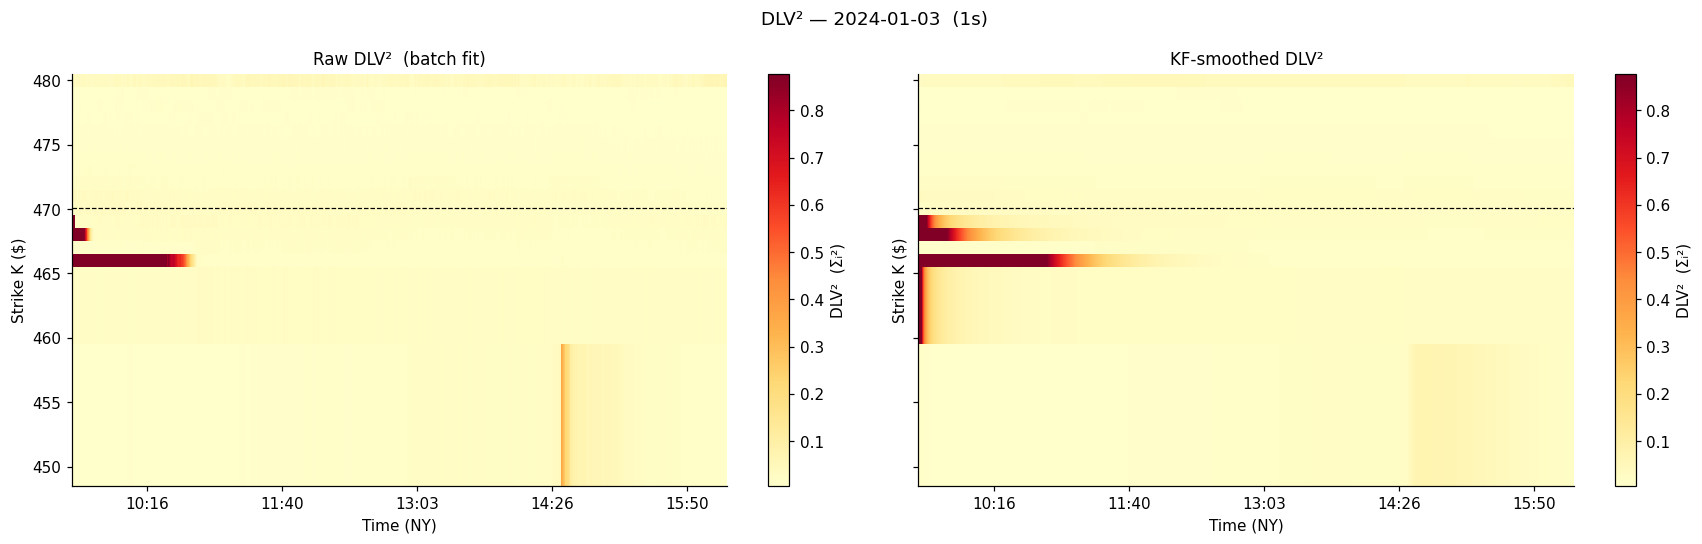

In [24]:
from matplotlib.ticker import FuncFormatter

fmt_hm = FuncFormatter(lambda x, _: _dt.datetime.fromtimestamp(x, tz=_ny).strftime("%H:%M"))

fig, axes = plt.subplots(1, 2, figsize=(16, 5), sharey=True)

for ax, mat, title in zip(
    axes,
    [raw_dlvsq.T, x_hist.T],
    ["Raw DLV²  (batch fit)", "KF-smoothed DLV²"],
):
    pcm = ax.pcolormesh(
        ts_hist,
        dlv_anchor_pure,
        mat,
        cmap="YlOrRd",
        shading="nearest",
        vmin=np.nanpercentile(raw_dlvsq, 1),
        vmax=np.nanpercentile(raw_dlvsq, 99),
    )
    fig.colorbar(pcm, ax=ax, label="DLV²  (Σᵢ²)")
    ax.xaxis.set_major_formatter(fmt_hm)
    ax.set_xlabel("Time (NY)")
    ax.set_ylabel("Strike K ($)")
    ax.set_title(title, fontsize=11)
    ax.axhline(ref_fwd, color="black", lw=0.8, ls="--", label="ATM")

fig.suptitle(f"DLV² — {TRADE_DATE}  ({BATCH_FREQ})", fontsize=12)
plt.tight_layout()
plt.show()

### 3b. DLV² time series — ATM ± strikes with ±1σ posterior band

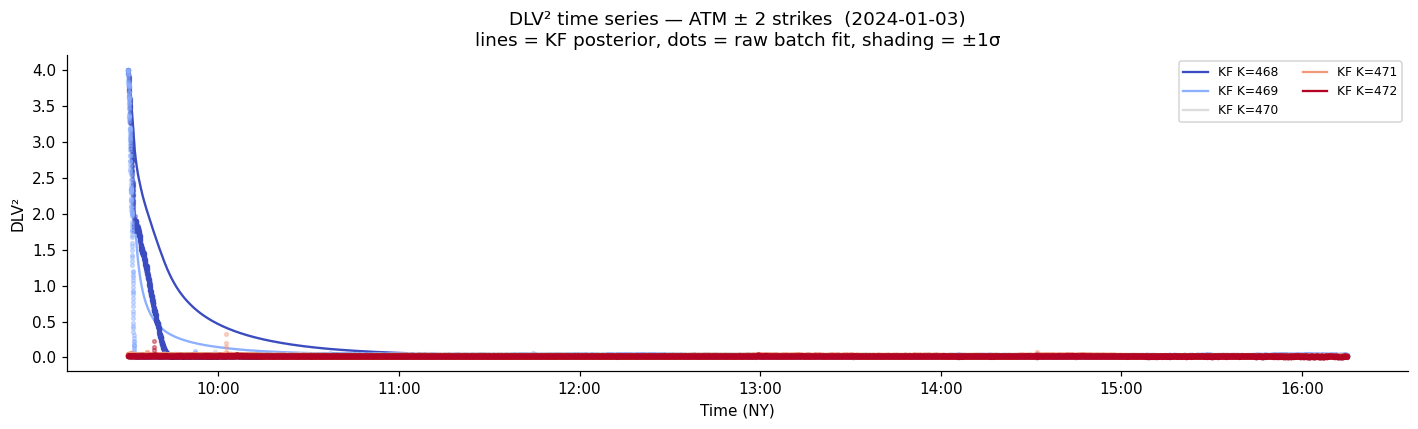

In [25]:
atm_idx = int(np.argmin(np.abs(dlv_anchor_pure - ref_fwd)))
n_lines = 5
sel_idx = np.clip(
    np.linspace(atm_idx - n_lines // 2, atm_idx + n_lines // 2, n_lines, dtype=int),
    0,
    N_dlv - 1,
)

t_plot = np.array([_dt.datetime.fromtimestamp(t, tz=_ny) for t in ts_hist])
colors = plt.cm.coolwarm(np.linspace(0, 1, n_lines))

fig, ax = plt.subplots(figsize=(13, 4))
for color, idx in zip(colors, sel_idx):
    K_lbl = dlv_anchor_pure[idx]
    sigma = np.sqrt(np.maximum(P_diag_hist[:, idx], 0))
    ax.plot(t_plot, x_hist[:, idx], color=color, lw=1.5, label=f"KF K={K_lbl:.0f}")
    ax.fill_between(t_plot, x_hist[:, idx] - sigma, x_hist[:, idx] + sigma, color=color, alpha=0.15)
    ax.scatter(
        t_plot[~failed_hist], raw_dlvsq[~failed_hist, idx], color=color, s=6, alpha=0.4, zorder=3
    )

ax.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter("%H:%M", tz=_ny))
ax.set_xlabel("Time (NY)")
ax.set_ylabel("DLV²")
ax.set_title(
    f"DLV² time series — ATM ± {n_lines // 2} strikes  ({TRADE_DATE})\n"
    "lines = KF posterior, dots = raw batch fit, shading = ±1σ"
)
ax.legend(fontsize=8, ncol=2)
plt.tight_layout()
plt.show()

### 3c. Innovation diagnostics  (z − x̂_pred)

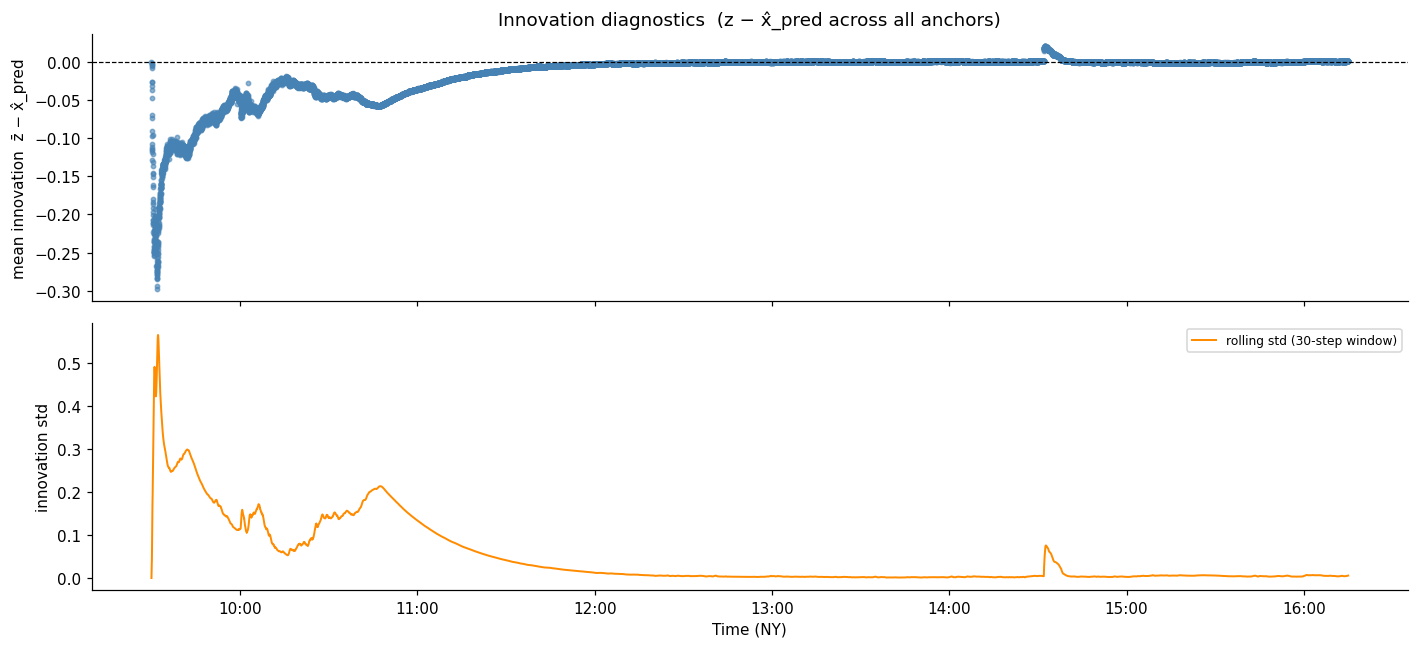

Innovation  mean=-1.6596e-02  std=9.8534e-02


In [26]:
# Mean innovation across strikes at each step
innov_mean = np.nanmean(innov_hist, axis=1)
innov_std = np.nanstd(innov_hist, axis=1)

# Rolling 30-step std
WIN = 30
roll_std = np.array(
    [np.nanstd(innov_hist[max(0, i - WIN) : i + 1].ravel()) for i in range(len(results))]
)

fig, axes = plt.subplots(2, 1, figsize=(13, 6), sharex=True)

axes[0].scatter(t_plot[~failed_hist], innov_mean[~failed_hist], s=8, color="steelblue", alpha=0.6)
axes[0].axhline(0, color="black", lw=0.8, ls="--")
axes[0].set_ylabel("mean innovation  z̄ − x̂_pred")
axes[0].set_title("Innovation diagnostics  (z − x̂_pred across all anchors)")

axes[1].plot(t_plot, roll_std, color="darkorange", lw=1.3, label=f"rolling std ({WIN}-step window)")
axes[1].set_ylabel("innovation std")
axes[1].set_xlabel("Time (NY)")
axes[1].legend(fontsize=8)

for ax in axes:
    ax.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter("%H:%M", tz=_ny))

plt.tight_layout()
plt.show()

valid_innov = innov_hist[~np.isnan(innov_hist)]
print(f"Innovation  mean={valid_innov.mean():.4e}  std={valid_innov.std():.4e}")

### 3d. Posterior uncertainty  √diag(P)  over time

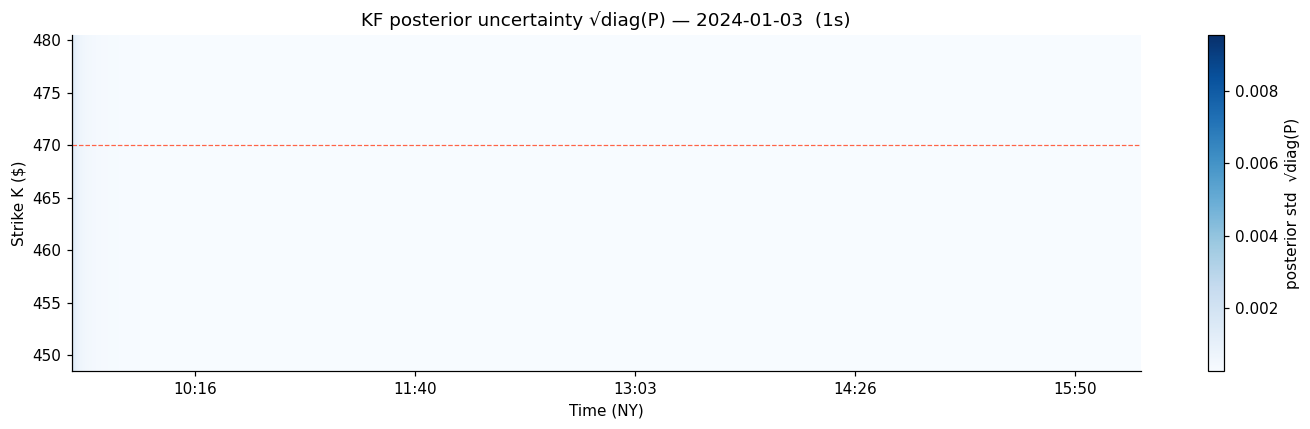

In [27]:
sigma_P = np.sqrt(np.maximum(P_diag_hist, 0))  # (T, N_dlv)

fig, ax = plt.subplots(figsize=(13, 4))
pcm = ax.pcolormesh(ts_hist, dlv_anchor_pure, sigma_P.T, cmap="Blues", shading="nearest")
fig.colorbar(pcm, ax=ax, label="posterior std  √diag(P)")
ax.xaxis.set_major_formatter(fmt_hm)
ax.set_xlabel("Time (NY)")
ax.set_ylabel("Strike K ($)")
ax.set_title(f"KF posterior uncertainty √diag(P) — {TRADE_DATE}  ({BATCH_FREQ})")
ax.axhline(ref_fwd, color="tomato", lw=0.8, ls="--", label="ATM")
plt.tight_layout()
plt.show()

### 3e. DLV² smoothing effect — raw vs KF scatter

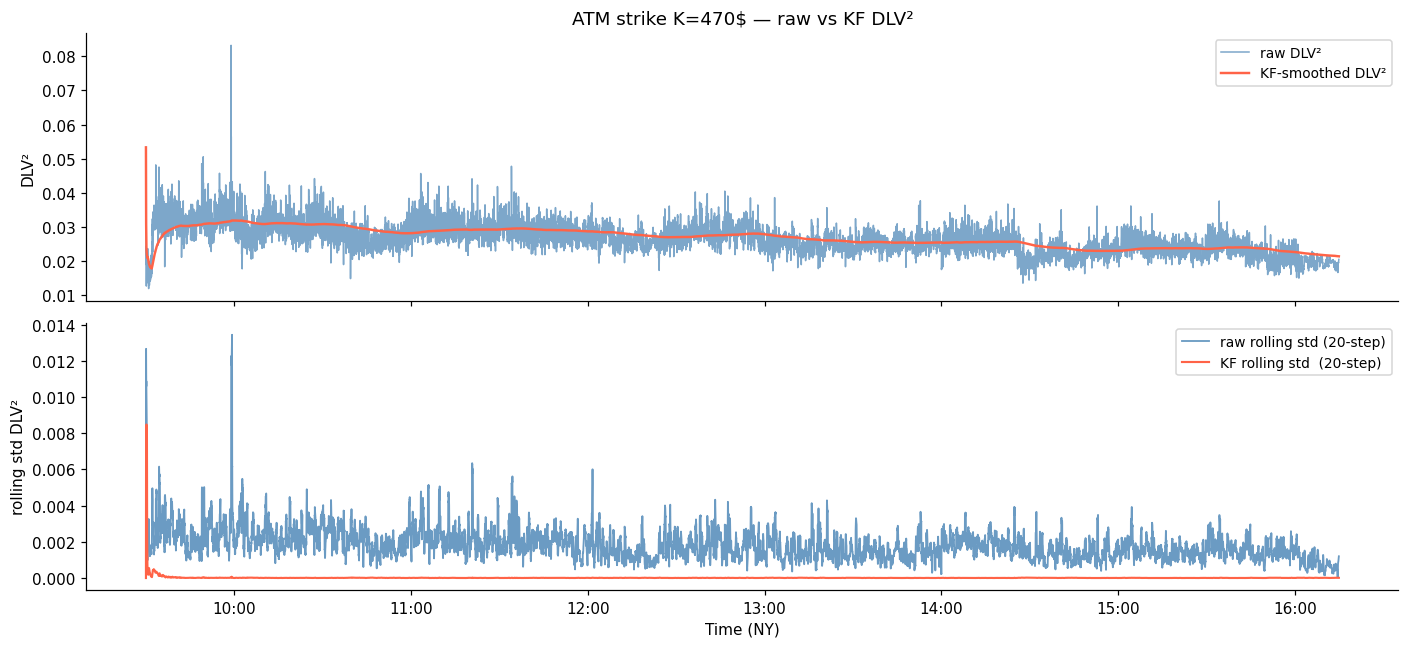

In [28]:
# For ATM anchor: raw vs KF-smoothed scatter + running std comparison
raw_atm = raw_dlvsq[:, atm_idx]
kf_atm = x_hist[:, atm_idx]

WIN2 = 20
raw_std = np.array([np.nanstd(raw_atm[max(0, i - WIN2) : i + 1]) for i in range(len(results))])
kf_std = np.array([np.nanstd(kf_atm[max(0, i - WIN2) : i + 1]) for i in range(len(results))])

fig, axes = plt.subplots(2, 1, figsize=(13, 6), sharex=True)

axes[0].plot(t_plot, raw_atm, lw=1.0, alpha=0.7, color="steelblue", label="raw DLV²")
axes[0].plot(t_plot, kf_atm, lw=1.6, color="tomato", label="KF-smoothed DLV²")
axes[0].set_ylabel("DLV²")
axes[0].set_title(f"ATM strike K={dlv_anchor_pure[atm_idx]:.0f}$ — raw vs KF DLV²")
axes[0].legend(fontsize=9)

axes[1].plot(
    t_plot, raw_std, lw=1.2, color="steelblue", alpha=0.8, label=f"raw rolling std ({WIN2}-step)"
)
axes[1].plot(t_plot, kf_std, lw=1.4, color="tomato", label=f"KF rolling std  ({WIN2}-step)")
axes[1].set_ylabel("rolling std DLV²")
axes[1].set_xlabel("Time (NY)")
axes[1].legend(fontsize=9)

for ax in axes:
    ax.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter("%H:%M", tz=_ny))

plt.tight_layout()
plt.show()

### 3f. IV smile snapshots (raw batch fit)

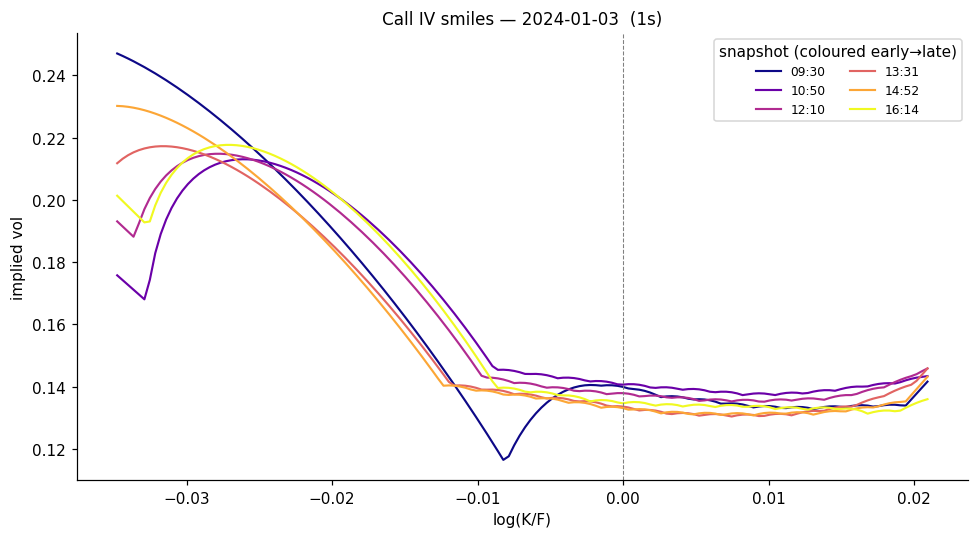

In [29]:
obs_lk_lo = float(np.log(interior_pure[0] / ref_fwd))
obs_lk_hi = float(np.log(interior_pure[-1] / ref_fwd))
lk_dense = np.linspace(obs_lk_lo, obs_lk_hi, 150)

viz_indices = np.linspace(0, len(good) - 1, min(N_VIZ, len(good)), dtype=int)
colors_viz = [plt.cm.plasma(i / max(len(viz_indices) - 1, 1)) for i in range(len(viz_indices))]

iv_fn = iv_from_norm_put if PUTS_ONLY else iv_from_norm_call
opt_type = "Put" if PUTS_ONLY else "Call"

fig, ax = plt.subplots(figsize=(9, 5))
ax.set_title(f"{opt_type} IV smiles — {TRADE_DATE}  ({BATCH_FREQ})", fontsize=11)
for i, color in zip(viz_indices, colors_viz):
    r = good[int(i)]
    fwd_r = r["fwd"]
    label = r["ts"].strftime("%H:%M") if hasattr(r["ts"], "strftime") else str(r["ts"])
    pk = fwd_r * np.exp(lk_dense)
    if PUTS_ONLY:
        prices = put_prices(r["densities"][0], grid_K, pk, fwd=fwd_r)
    else:
        prices = call_prices(r["densities"][0], grid_K, pk)
    ivs = np.array([iv_fn(float(p), float(k), r["T"], fwd_r) for p, k in zip(prices, lk_dense)])
    mask = np.isfinite(ivs) & (ivs > 0)
    ax.plot(lk_dense[mask], ivs[mask], color=color, lw=1.4, label=label)

ax.set_xlabel("log(K/F)")
ax.set_ylabel("implied vol")
ax.axvline(0, color="gray", lw=0.7, ls="--")
ax.legend(fontsize=8, ncol=2, title="snapshot (coloured early→late)")
plt.tight_layout()
plt.show()

In [44]:
lk_dense.shape

(150,)

### 3g. Density snapshots — 4 intraday timestamps

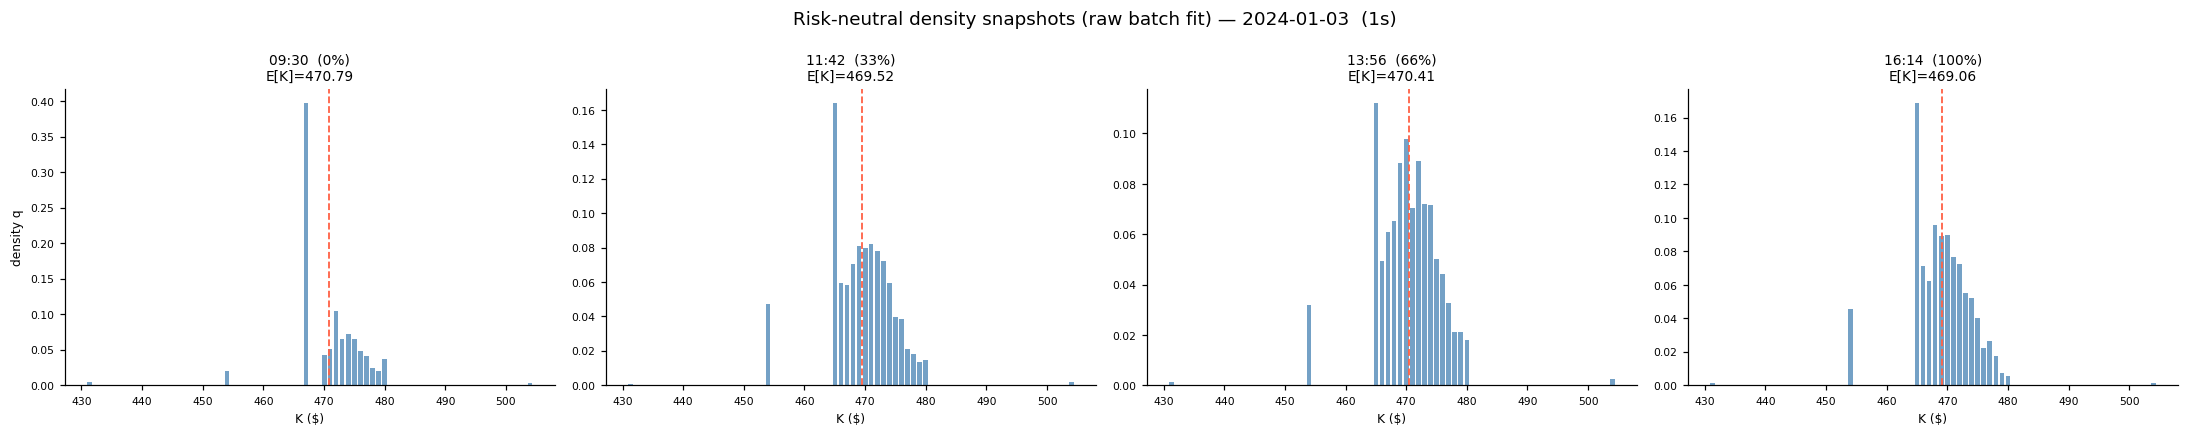

In [30]:
snap_fracs = [0.00, 0.33, 0.66, 1.00]
good_idxs = [i for i, r in enumerate(results) if not r["failed"]]
snap_idxs = [good_idxs[int(f * (len(good_idxs) - 1))] for f in snap_fracs]
bar_w = 0.8 * np.min(np.diff(anchor_pure))

fig, axes = plt.subplots(1, 4, figsize=(20, 4))
for ax, (idx, frac) in zip(axes, zip(snap_idxs, snap_fracs)):
    r = results[idx]
    d = r["densities"][0]
    fwd_r = r["fwd"]
    ts_lbl = r["ts"].strftime("%H:%M") if hasattr(r["ts"], "strftime") else str(r["ts"])
    mart = float(np.dot(anchor_pure, d))
    ax.bar(anchor_pure, d, width=bar_w, color="steelblue", alpha=0.75)
    ax.axvline(fwd_r, color="tomato", lw=1.2, ls="--", label=f"F={fwd_r:.1f}")
    ax.set_title(f"{ts_lbl}  ({frac:.0%})\nE[K]={mart:.2f}", fontsize=9)
    ax.set_xlabel("K ($)", fontsize=8)
    if ax is axes[0]:
        ax.set_ylabel("density q", fontsize=8)
    ax.tick_params(labelsize=7)

fig.suptitle(
    f"Risk-neutral density snapshots (raw batch fit) — {TRADE_DATE}  ({BATCH_FREQ})", fontsize=12
)
plt.tight_layout()
plt.show()

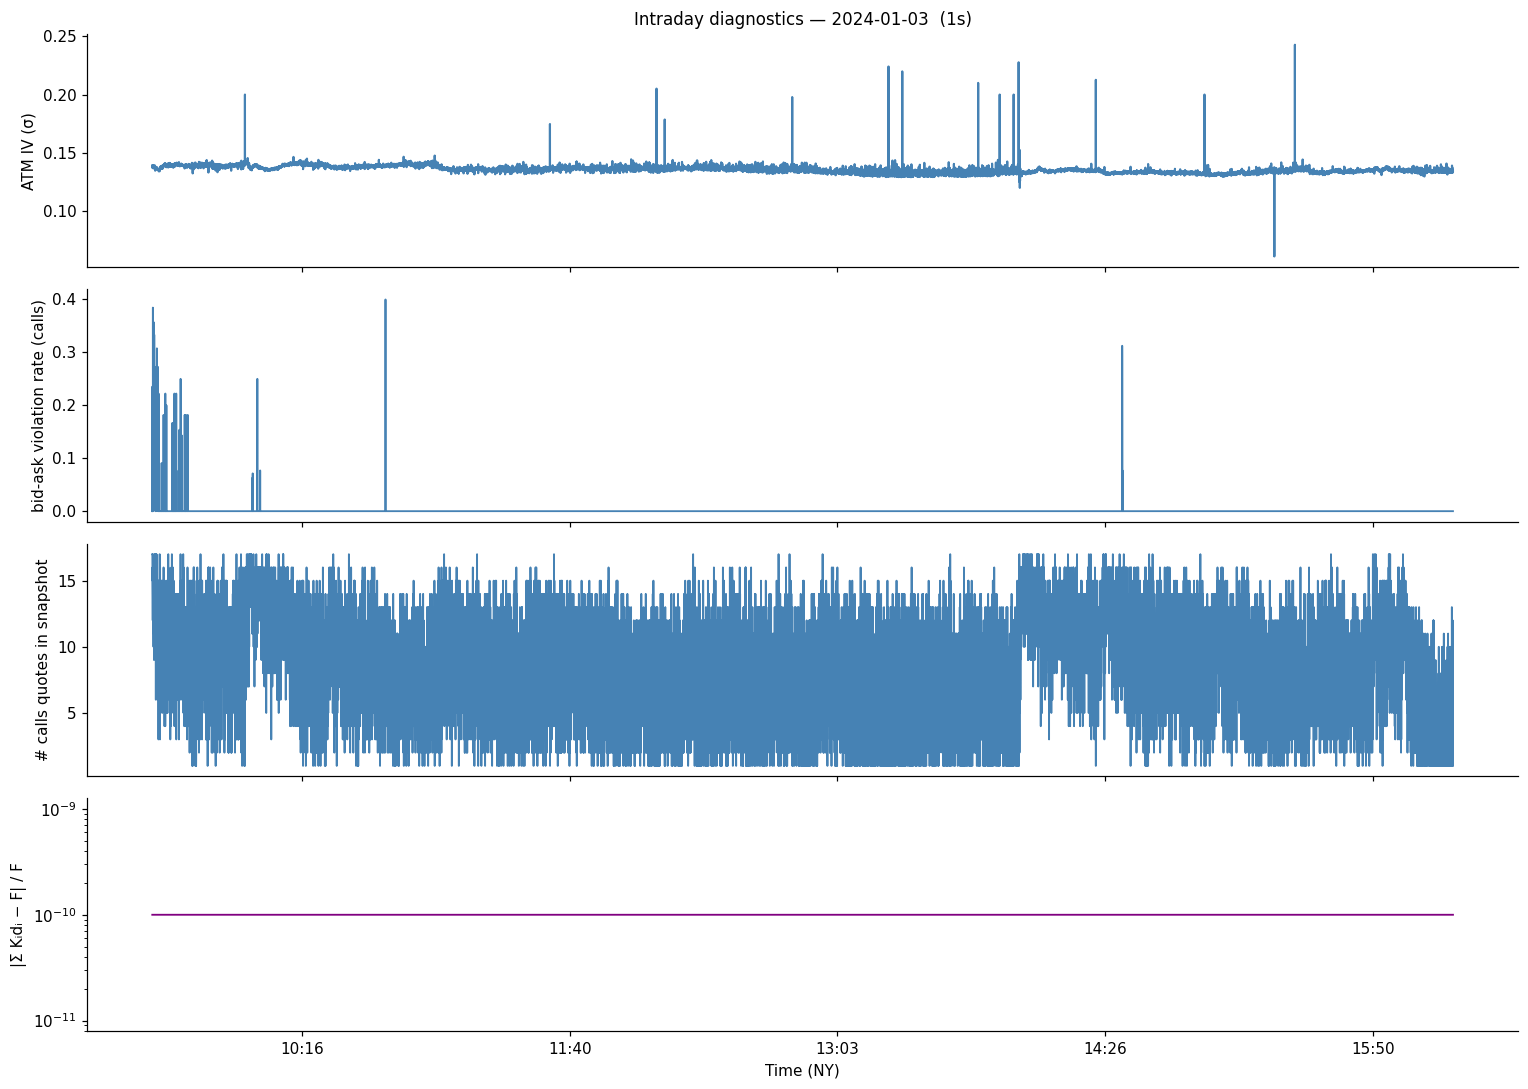

In [31]:
snap_data = snaps_puts if PUTS_ONLY else snaps_calls
opt_label = "puts" if PUTS_ONLY else "calls"

mart_res, viol_obs, atm_iv_list, n_obs_list = [], [], [], []

for r in results:
    atm_iv_list.append(r["atm_iv"])
    n_obs_list.append(r["n_puts"] if PUTS_ONLY else r["n_calls"])

    if r["densities"] is not None:
        d = r["densities"][0]
        fwd_r = r["fwd"]
        mart_res.append(float(np.abs(anchor_pure @ d - fwd_r) / fwd_r))

        snap = snap_data.filter(pl.col("batch_ts") == r["ts"]).sort("pure_strike")
        if not snap.is_empty():
            pk = snap["pure_strike"].to_numpy().astype(float)
            bid = snap["bid_norm"].to_numpy().astype(float)
            ask = snap["ask_norm"].to_numpy().astype(float)
            isc = np.zeros(len(pk), dtype=bool) if PUTS_ONLY else np.ones(len(pk), dtype=bool)
            fit = option_prices(d, grid_K, pk, isc, fwd=fwd_r)
            viol_obs.append(float(((fit < bid) | (fit > ask)).mean()))
        else:
            viol_obs.append(np.nan)
    else:
        mart_res.append(np.nan)
        viol_obs.append(np.nan)

from matplotlib.ticker import FuncFormatter as _FF

fmt2 = _FF(lambda x, _: _dt.datetime.fromtimestamp(x, tz=_ny).strftime("%H:%M"))

fig, axes = plt.subplots(4, 1, figsize=(14, 10), sharex=True)
axes[0].plot(ts_hist, atm_iv_list, color="steelblue", lw=1.4)
axes[0].set_ylabel("ATM IV (σ)")
axes[0].set_title(f"Intraday diagnostics — {TRADE_DATE}  ({BATCH_FREQ})", fontsize=11)

axes[1].plot(ts_hist, viol_obs, color="steelblue", lw=1.2)
axes[1].set_ylabel(f"bid-ask violation rate ({opt_label})")

axes[2].plot(ts_hist, n_obs_list, color="steelblue", lw=1.2)
axes[2].set_ylabel(f"# {opt_label} quotes in snapshot")

axes[3].semilogy(ts_hist, np.maximum(mart_res, 1e-10), color="purple", lw=1.2)
axes[3].set_ylabel("|Σ Kᵢdᵢ − F| / F")

for ax in axes:
    ax.xaxis.set_major_formatter(fmt2)
axes[-1].set_xlabel("Time (NY)")
plt.tight_layout()
plt.show()

## Section 4 — Option pricing evaluation

Reconstruct market option prices from the fitted (raw batch) densities and measure
how accurately the SANOS model reproduces the observed bid/ask quotes.

- **4a** Compute per-snapshot RMSE, MAE, and bid-ask violation rate.
- **4b** Plot those metrics as time series.
- **4c** Inspect a single snapshot: market quotes vs reconstructed prices + residuals.

### 4a. Per-snapshot pricing errors

In [ ]:
eval_records = []

for k, r in enumerate(results):
    if r["failed"] or r["densities"] is None:
        continue

    density = r["densities"][0]
    fwd_r = r["fwd"]
    ts_r = r["ts"]

    snap_c = snaps_calls.filter(pl.col("batch_ts") == ts_r).sort("pure_strike")
    snap_p = snaps_puts.filter(pl.col("batch_ts") == ts_r).sort("pure_strike")

    parts = []
    if not snap_c.is_empty() and not PUTS_ONLY:
        parts.append(snap_c.with_columns(pl.lit(True).alias("is_call")))
    if not snap_p.is_empty() and not CALLS_ONLY:
        parts.append(snap_p.with_columns(pl.lit(False).alias("is_call")))

    if not parts:
        continue

    snap_obs = pl.concat(parts).sort("pure_strike")
    strikes_obs = snap_obs["pure_strike"].to_numpy().astype(float)
    bid_obs = snap_obs["bid_norm"].to_numpy().astype(float)
    ask_obs = snap_obs["ask_norm"].to_numpy().astype(float)
    mid_obs = 0.5 * (bid_obs + ask_obs)
    is_call_obs = snap_obs["is_call"].to_numpy().astype(bool)

    model_px = option_prices(density, grid_K, strikes_obs, is_call_obs, fwd_r)
    resid = model_px - mid_obs
    half_spread = 0.5 * (ask_obs - bid_obs)

    eval_records.append(
        dict(
            k=k,
            ts_s=ts_hist[k],
            rmse=float(np.sqrt((resid**2).mean())),
            mae=float(np.abs(resid).mean()),
            med_ae=float(np.median(np.abs(resid))),
            viol_rate=float((np.abs(resid) > half_spread).mean()),
            n_obs=len(strikes_obs),
        )
    )

eval_arr = {col: np.array([d[col] for d in eval_records]) for col in eval_records[0]}

print(f"Evaluated {len(eval_records):,} snapshots")
print(f"Mean RMSE            : {eval_arr['rmse'].mean():.5f}  $/df")
print(f"Mean MAE             : {eval_arr['mae'].mean():.5f}  $/df")
print(f"Median of median-AE  : {np.median(eval_arr['med_ae']):.5f}  $/df")
print(f"Mean b/a viol. rate  : {eval_arr['viol_rate'].mean():.2%}")
print(f"Mean # obs / snapshot: {eval_arr['n_obs'].mean():.0f}")

### 4b. Pricing metrics over time

In [ ]:
t_eval = np.array([_dt.datetime.fromtimestamp(s, tz=_ny) for s in eval_arr["ts_s"]])
fmt_eval = plt.matplotlib.dates.DateFormatter("%H:%M", tz=_ny)

fig, axes = plt.subplots(3, 1, figsize=(13, 8), sharex=True)

axes[0].plot(t_eval, eval_arr["rmse"], lw=1.1, color="steelblue")
axes[0].set_ylabel("RMSE  ($/df)")
axes[0].set_title(
    f"Option pricing accuracy — {TRADE_DATE}  ({BATCH_FREQ})\n"
    "prices reconstructed from batch-fit density vs market mid",
    fontsize=11,
)

axes[1].plot(t_eval, eval_arr["mae"], lw=1.1, color="darkorange", label="MAE")
axes[1].plot(
    t_eval, eval_arr["med_ae"], lw=1.0, color="goldenrod", alpha=0.7, label="median |error|"
)
axes[1].set_ylabel("$/df")
axes[1].legend(fontsize=8)

axes[2].plot(t_eval, eval_arr["viol_rate"] * 100, lw=1.1, color="crimson")
axes[2].set_ylabel("bid-ask violations (%)")
axes[2].set_xlabel("Time (NY)")

for ax in axes:
    ax.xaxis.set_major_formatter(fmt_eval)

plt.tight_layout()
plt.show()

### 4c. Snapshot price reconstruction

Change `EVAL_SNAP_IDX` to any index in `good_idxs` to inspect a different timestamp.

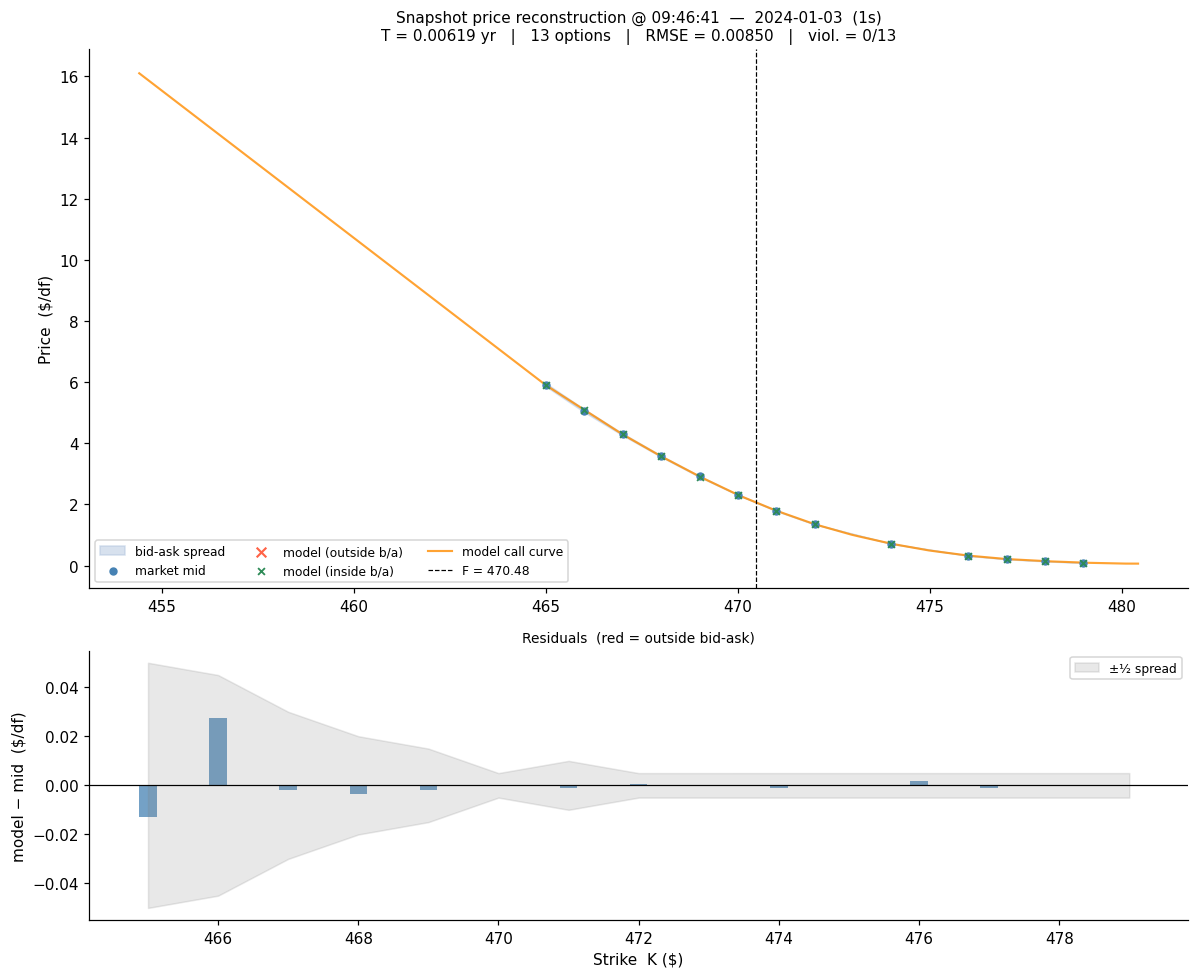

In [42]:
EVAL_SNAP_IDX = 1000  # good_idxs[len(good_idxs) // 2]  # default: midday snapshot

r_snap = results[EVAL_SNAP_IDX]
density_snap = r_snap["densities"][0]
fwd_snap_e = r_snap["fwd"]
T_snap_e = r_snap["T"]
ts_lbl_e = (
    r_snap["ts"].strftime("%H:%M:%S") if hasattr(r_snap["ts"], "strftime") else str(r_snap["ts"])
)

# Market quotes for this snapshot
snap_c_e = snaps_calls.filter(pl.col("batch_ts") == r_snap["ts"]).sort("pure_strike")
snap_p_e = snaps_puts.filter(pl.col("batch_ts") == r_snap["ts"]).sort("pure_strike")

parts_e = []
if not snap_c_e.is_empty() and not PUTS_ONLY:
    parts_e.append(snap_c_e.with_columns(pl.lit(True).alias("is_call")))
if not snap_p_e.is_empty() and not CALLS_ONLY:
    parts_e.append(snap_p_e.with_columns(pl.lit(False).alias("is_call")))

snap_obs_e = pl.concat(parts_e).sort("pure_strike")
strikes_e = snap_obs_e["pure_strike"].to_numpy().astype(float)
bid_e = snap_obs_e["bid_norm"].to_numpy().astype(float)
ask_e = snap_obs_e["ask_norm"].to_numpy().astype(float)
mid_e = 0.5 * (bid_e + ask_e)
is_call_e = snap_obs_e["is_call"].to_numpy().astype(bool)

model_px_e = option_prices(density_snap, grid_K, strikes_e, is_call_e, fwd_snap_e)
resid_e = model_px_e - mid_e
half_spread_e = 0.5 * (ask_e - bid_e)
outside_mask = np.abs(resid_e) > half_spread_e

# Dense model price curve — same type as the fit (call if CALLS_ONLY, put if PUTS_ONLY)
k_dense_e = fwd_snap_e * np.exp(np.linspace(obs_lk_lo, obs_lk_hi, 250))
if PUTS_ONLY:
    model_curve_e = put_prices(density_snap, grid_K, k_dense_e, fwd_snap_e)
    curve_label = "model put curve"
else:
    model_curve_e = call_prices(density_snap, grid_K, k_dense_e)
    curve_label = "model call curve"

fig, axes = plt.subplots(2, 1, figsize=(11, 9), gridspec_kw={"height_ratios": [3, 1.5]})

# ── top: price reconstruction ──────────────────────────────────────────────
ax = axes[0]
ax.fill_between(strikes_e, bid_e, ask_e, color="lightsteelblue", alpha=0.5, label="bid-ask spread")
ax.scatter(strikes_e, mid_e, s=20, color="steelblue", zorder=4, label="market mid")
ax.scatter(
    strikes_e[outside_mask],
    model_px_e[outside_mask],
    s=40,
    marker="x",
    color="tomato",
    zorder=6,
    lw=1.4,
    label="model (outside b/a)",
)
ax.scatter(
    strikes_e[~outside_mask],
    model_px_e[~outside_mask],
    s=20,
    marker="x",
    color="seagreen",
    zorder=5,
    lw=1.2,
    label="model (inside b/a)",
)
ax.plot(k_dense_e, model_curve_e, color="darkorange", lw=1.4, alpha=0.8, label=curve_label)
ax.axvline(fwd_snap_e, color="black", lw=0.8, ls="--", label=f"F = {fwd_snap_e:.2f}")
ax.set_ylabel("Price  ($/df)")
ax.set_title(
    f"Snapshot price reconstruction @ {ts_lbl_e}  —  {TRADE_DATE}  ({BATCH_FREQ})\n"
    f"T = {T_snap_e:.5f} yr   |   {len(strikes_e)} options   |   "
    f"RMSE = {np.sqrt((resid_e**2).mean()):.5f}   |   "
    f"viol. = {outside_mask.sum()}/{len(strikes_e)}",
    fontsize=10,
)
ax.legend(fontsize=8, ncol=3)

# ── bottom: residuals ──────────────────────────────────────────────────────
ax2 = axes[1]
colors_bar = np.where(outside_mask, "tomato", "steelblue")
ax2.bar(strikes_e, resid_e, width=0.25, color=colors_bar, alpha=0.75)
ax2.fill_between(
    strikes_e, -half_spread_e, half_spread_e, color="gray", alpha=0.18, label="±½ spread"
)
ax2.axhline(0, color="black", lw=0.8)
ax2.set_xlabel("Strike  K ($)")
ax2.set_ylabel("model − mid  ($/df)")
ax2.set_title("Residuals  (red = outside bid-ask)", fontsize=9)
ax2.legend(fontsize=8)

plt.tight_layout()
plt.show()